# P6 — Operasi Morfologi dan Komponen Terhubung (SIMUTEH)
**Muhammad Imam Faisal — NIM 2330511016 — Kelas 7A — SEED 1016**

Bagian 3: operasi morfologi. Bagian 4: komponen terhubung dan pengukuran. Bagian 5: modul `bercak.py`.

### Persiapan: Kode 1.1 dan `tepi_canny` dari Kode 1.3 (dijalankan ulang)

In [21]:
import sys, os, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

os.makedirs("../hasil", exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

# praproses semua citra sekali saja agar eksperimen tidak mengulang pekerjaan yang sama
PRA = {n: praproses(muat(n)[0], PARAM) for n in label.nama_file}
print(len(PRA), "citra siap")

60 citra siap


## Bagian 3. Operasi Morfologi pada Citra Biner
### Verifikasi Lembar Hitung 3.1 (SE persegi 3×3, luar citra = 0)

In [22]:
B = np.array([[0,0,0,0,0,0,0,0,0],
              [0,1,1,1,0,0,0,0,0],
              [0,1,0,1,0,0,0,1,0],
              [0,1,1,1,0,0,0,0,0],
              [0,0,0,0,1,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,1,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0]], np.uint8)
se3 = np.ones((3, 3), np.uint8)
bb = dict(borderType=cv2.BORDER_CONSTANT, borderValue=0)     # piksel di luar citra = 0
er = lambda x: cv2.erode(x, se3, **bb); di = lambda x: cv2.dilate(x, se3, **bb)
op = lambda x: di(er(x)); cl = lambda x: er(di(x))
n_k = lambda x, c: cv2.connectedComponents(x, connectivity=c)[0] - 1
print("a) komponen konektivitas 4 =", n_k(B, 4), "| konektivitas 8 =", n_k(B, 8))
for nm, x in [("b) erosi", er(B)), ("b) opening", op(B)), ("c) closing", cl(B)), ("d) closing lalu opening", op(cl(B)))]:
    print(f"{nm}  (komponen-8 = {n_k(x, 8)})"); print(x)

a) komponen konektivitas 4 = 4 | konektivitas 8 = 3
b) erosi  (komponen-8 = 0)
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
b) opening  (komponen-8 = 0)
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
c) closing  (komponen-8 = 2)
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]
d) closing lalu opening  (komponen-8 = 1)
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]


### Kode 3.1 Mask daun awal dan bercak awal

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.998                   119              11           0.606
1  teh_021.png          0.998                    91               3           0.203
2  teh_011.png          0.999                   111               0               -


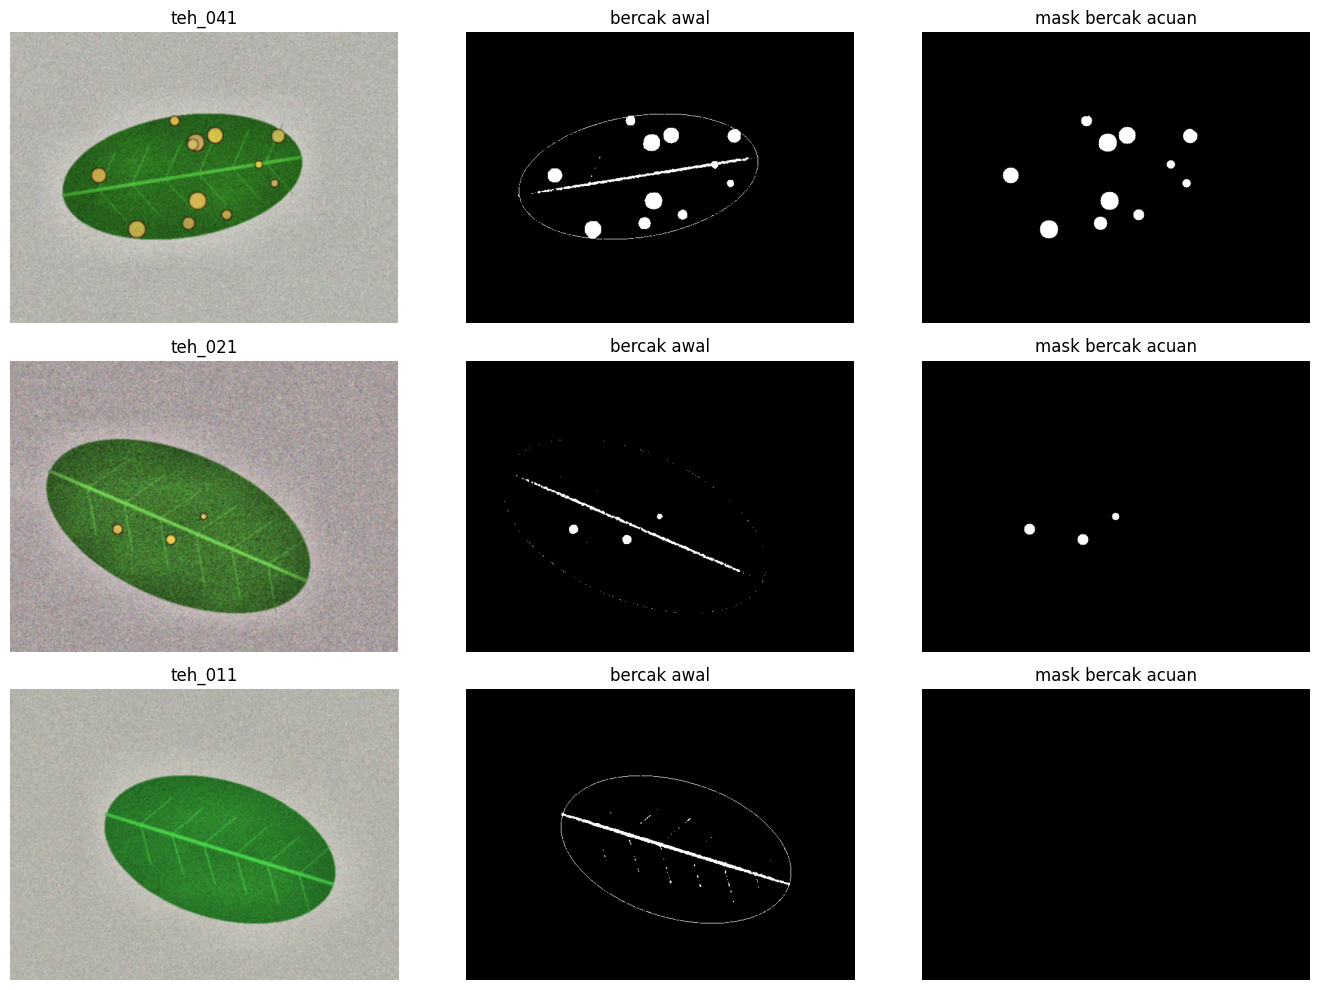

In [23]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:     # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = PRA[nama]
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))
plt.savefig("../hasil/p6_bercak_awal.png", dpi=110, bbox_inches="tight")

### Kode 3.2 Erosi, dilasi, opening, dan closing (SE elips 5×5)

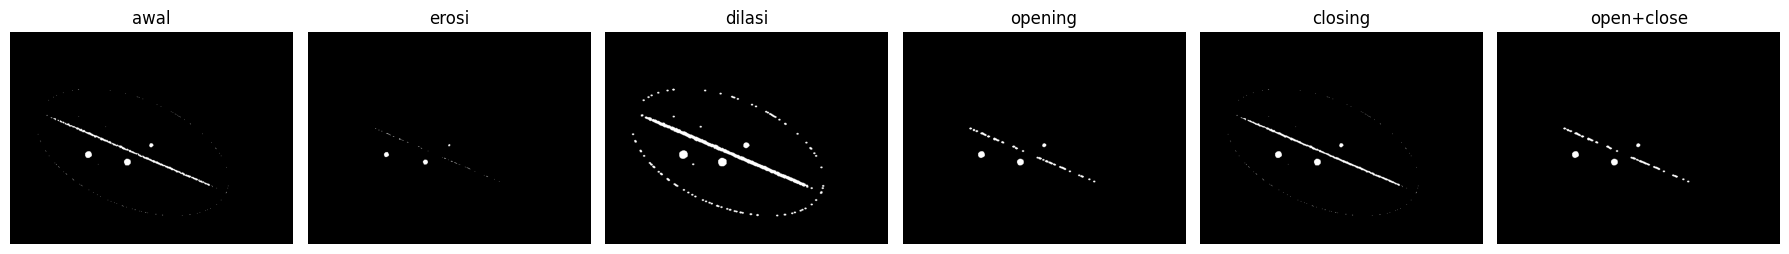

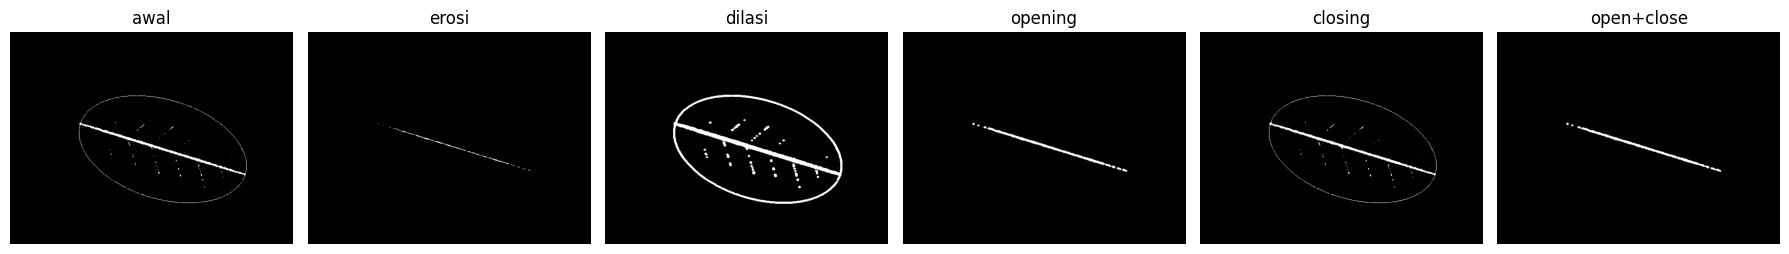

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal        91    1975  0.203
1   teh_021.png       erosi        30     292  0.307
2   teh_021.png      dilasi        65    5270  0.117
3   teh_021.png     opening        20    1090  0.333
4   teh_021.png     closing        88    2074  0.194
5   teh_021.png  open+close        15    1130  0.323
6   teh_011.png        awal       111    2973      -
7   teh_011.png       erosi        18     451      -
8   teh_011.png      dilasi        28    9470      -
9   teh_011.png     opening         7    1742      -
10  teh_011.png     closing        96    3053      -
11  teh_011.png  open+close         5    1764      -


In [24]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = PRA[nama]
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.savefig(f"../hasil/p6_operasi_{nama[:7]}.png", dpi=110, bbox_inches="tight"); plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

### Kode 3.3 Eksperimen k, bentuk, dan ukuran SE (60 citra)

In [25]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = PRA[d.nama_file]
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.58   0.17        23.10  16.40  18.20
          5       0.60   0.24         2.95   4.30   4.60
          7       0.66   0.41         1.40   2.55   1.90
  persegi 3       0.59   0.19         7.75   8.30   7.40
          5       0.62   0.33         2.75   3.15   3.20
          7       0.64   0.47         0.90   0.50   0.00
  silang  3       0.58   0.17        23.10  16.40  18.20
          5       0.62   0.24         6.20   8.20   7.40
          7       0.68   0.39         2.10   4.80   3.95
4 elips   3       0.62   0.28        16.70  11.60  11.60
          5       0.63   0.37         2.65   2.85   2.40
          7       0.64   0.47         0.85   0.75   0.90
  persegi 3       0.62   0.30         6.45   7.00   6.95
          5       0.64   0.43         1.30   2.35   1.05
          7       0.60   0.43  

#### Tabel 9. Ringkasan eksperimen SE untuk k = 4

In [26]:
def ringkas_se(df):
    t = df.pivot_table(index=["bentuk", "ukuran"], columns="kelas", values=["IoU", "galat_jumlah"], sort=False)
    out = pd.DataFrame({"IoU berat": t[("IoU", "berat")], "IoU ringan": t[("IoU", "ringan")],
                        "Galat jumlah berat": t[("galat_jumlah", "berat")],
                        "Galat jumlah ringan": t[("galat_jumlah", "ringan")],
                        "Galat jumlah sehat": t[("galat_jumlah", "sehat")]})
    return out.reindex(["persegi", "elips", "silang"], level=0).round(3)

tabel9 = ringkas_se(eks[eks.k == 4])
tabel9.to_csv("../hasil/p6_tabel9_se_k4.csv")
tabel9

IoU berat  IoU ringan  Galat jumlah berat  Galat jumlah ringan  Galat jumlah sehat
bentuk  ukuran                                                                                    
persegi 3           0.622       0.302                6.45                 7.00                6.95
        5           0.636       0.429                1.30                 2.35                1.05
        7           0.600       0.431                1.30                 0.55                0.00
elips   3           0.617       0.277               16.70                11.60               11.60
        5           0.632       0.370                2.65                 2.85                2.40
        7           0.635       0.472                0.85                 0.75                0.90
silang  3           0.617       0.277               16.70                11.60               11.60
        5           0.649       0.366                5.10                 4.95                4.55
        7           0.651       0.449                0.65                 1.35                1.35

#### Ringkasan semua k (bahan memilih k): rerata IoU berbercak dan galat jumlah per kelas

In [27]:
semua_k = eks.groupby(["k", "bentuk", "ukuran"]).apply(
    lambda t: pd.Series({"IoU_berbercak": t.IoU.mean(),
                         "galat_berat": t[t.kelas == "berat"].galat_jumlah.mean(),
                         "galat_ringan": t[t.kelas == "ringan"].galat_jumlah.mean(),
                         "galat_sehat": t[t.kelas == "sehat"].galat_jumlah.mean(),
                         "galat_total": t.galat_jumlah.mean()}), include_groups=False).round(3)
semua_k.to_csv("../hasil/p6_ringkas_semua_k.csv")
semua_k.sort_values(["galat_total", "IoU_berbercak"], ascending=[True, False]).head(10)

IoU_berbercak  galat_berat  galat_ringan  galat_sehat  galat_total
k bentuk  ukuran                                                                    
3 persegi 7               0.552         0.90          0.50         0.00        0.467
4 persegi 7               0.516         1.30          0.55         0.00        0.617
6 silang  7               0.478         1.75          0.10         0.00        0.617
  persegi 5               0.504         1.80          0.20         0.05        0.683
  elips   7               0.487         1.85          0.30         0.00        0.717
4 elips   7               0.553         0.85          0.75         0.90        0.833
6 elips   5               0.518         1.65          0.45         0.90        1.000
  persegi 7               0.419         2.45          0.80         0.00        1.083
4 silang  7               0.550         0.65          1.35         1.35        1.117
6 silang  5               0.522         1.45          0.85         1.25        1.183

### Kode 3.4 Gradien morfologi dibandingkan dengan Canny (batas daun saja)

In [28]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = PRA[d.nama_file]
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))   # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
gm = pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"]).groupby("kondisi").mean().round(3)
gm.to_csv("../hasil/p6_gradien_morfologi.csv")
print(gm)

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.749     0.721
gelap                          0.971     0.685
kontras_rendah                 0.290     0.860
normal                         0.981     0.681
terang                         0.854     0.693


#### Bahan P3.5: mutu `mask_daun_awal` (Otsu kanal S) per kondisi cahaya

In [29]:
baris = []
for _, d in label.iterrows():
    _, md, _ = muat(d.nama_file)
    baris.append([d.kondisi_cahaya, iou(mask_daun_awal(PRA[d.nama_file]), md)])
iou_daun = pd.DataFrame(baris, columns=["kondisi", "IoU"]).groupby("kondisi").IoU.agg(["mean", "min"]).round(3)
iou_daun.to_csv("../hasil/p6_iou_mask_daun.csv")
iou_daun

,mean,min
kondisi,,
bayangan,0.990,0.980
gelap,0.996,0.990
kontras_rendah,0.894,0.722
normal,0.997,0.993
terang,0.992,0.978


### Langkah 3.6 (Kerjakan sendiri) Panel bentuk SE

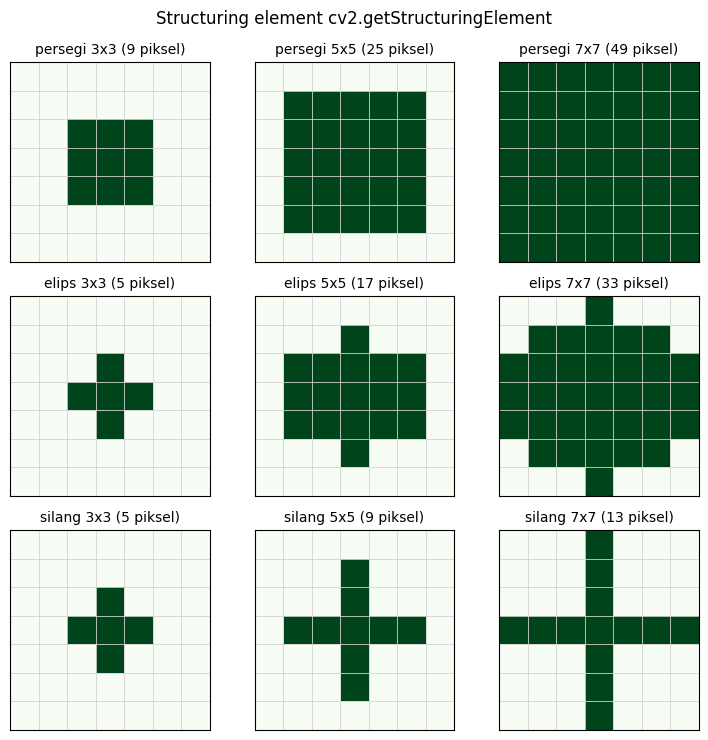

elips 3x3 == silang 3x3 ? True
[[0 1 0]
 [1 1 1]
 [0 1 0]]


In [30]:
fig, ax = plt.subplots(3, 3, figsize=(7.5, 7.5))
for i, (nb, kb) in enumerate(bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        s = cv2.getStructuringElement(kb, (uk, uk))
        pad = np.zeros((7, 7), np.uint8); o = (7 - uk) // 2
        pad[o:o + uk, o:o + uk] = s                       # tengahkan agar skala sama
        ax[i, j].imshow(pad, cmap="Greens", vmin=0, vmax=1)
        ax[i, j].set_xticks(np.arange(-.5, 7, 1), minor=True); ax[i, j].set_yticks(np.arange(-.5, 7, 1), minor=True)
        ax[i, j].grid(which="minor", color="lightgray", lw=0.6); ax[i, j].tick_params(which="both", length=0)
        ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        ax[i, j].set_title(f"{nb} {uk}x{uk} ({int(s.sum())} piksel)", fontsize=10)
plt.suptitle("Structuring element cv2.getStructuringElement"); plt.tight_layout()
plt.savefig("../hasil/p6_bentuk_se.png", dpi=150); plt.show()
print("elips 3x3 == silang 3x3 ?", np.array_equal(SE(3, cv2.MORPH_ELLIPSE), SE(3, cv2.MORPH_CROSS)))
print(SE(3, cv2.MORPH_ELLIPSE))

## Bagian 4. Komponen Terhubung dan Pengukuran Bercak
### Verifikasi Lembar Hitung 4.1

In [31]:
MM_PER_PX = 0.4375                # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def keliling_sisi(m):
    """Keliling = jumlah sisi piksel yang berbatasan dengan latar (cara lembar hitung)."""
    p = np.pad(m.astype(int), 1)
    return int(sum(((p[1:-1, 1:-1] == 1) & (np.roll(p, s, a)[1:-1, 1:-1] == 0)).sum()
                   for s, a in [(1, 0), (-1, 0), (1, 1), (-1, 1)]))

for nm, (h, w) in [("bercak 3x3", (3, 3)), ("garis 1x6", (1, 6))]:
    m = np.zeros((9, 9), np.uint8); m[1:1 + h, 1:1 + w] = 1
    A, P = int(m.sum()), keliling_sisi(m)
    kont, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    Pcv = cv2.arcLength(kont[0], True)
    print(f"{nm}: luas {A} px = {A * MM_PER_PX**2:.2f} mm2 | keliling sisi {P}, kebulatan {4*np.pi*A/P**2:.3f}, "
          f"rasio {max(h, w)/min(h, w):.1f} | OpenCV: keliling {Pcv:.0f}, kebulatan {4*np.pi*A/Pcv**2:.3f}")

bercak 3x3: luas 9 px = 1.72 mm2 | keliling sisi 12, kebulatan 0.785, rasio 1.0 | OpenCV: keliling 8, kebulatan 1.767
garis 1x6: luas 6 px = 1.15 mm2 | keliling sisi 14, kebulatan 0.385, rasio 6.0 | OpenCV: keliling 10, kebulatan 0.754


### Kode 4.1 Komponen terhubung dan pengukuran setiap bercak (teh_041)

konektivitas 4: 22 komponen
konektivitas 8: 21 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      206     39.43         51.0       1.00         1.07  270  145
1       2      525    100.49         82.8       0.96         1.04  337  170
2       3      387     74.07         70.5       0.98         1.10  442  170
3       4      632    120.97         93.0       0.92         1.04  305  182
4       5       48      9.19         31.8       0.60         2.38  442  211
5       6      299     57.23        138.1       0.20         5.07  405  218
6       7        1      0.19          0.0       0.00         0.00  435  213
7       8      200     38.28        101.6       0.24         8.49  348  227
8       9      452     86.52         76.5       0.97         1.05  146  236
9      10       53     10.14         28.5       0.82         2.20  315  232
10     11       28      5.36         18.5       1.03         1.67  283  237
11     12      194     37.13    

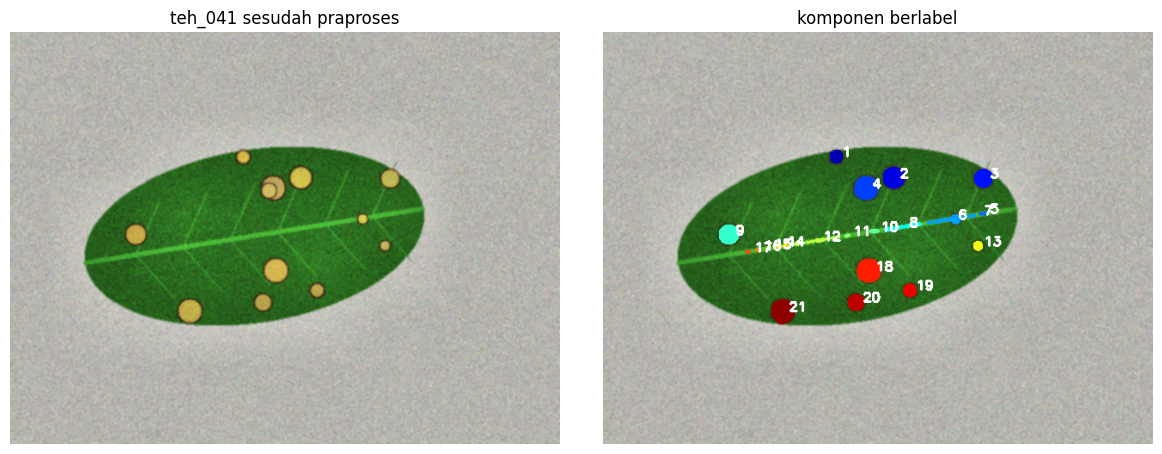

In [32]:
def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = PRA["teh_041.png"]
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)
tabel_kom.to_csv("../hasil/p6_tabel10_teh041.csv", index=False)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
plt.savefig("../hasil/p6_teh041_berlabel.png", dpi=130, bbox_inches="tight")

#### Bahan P4.4: luas total bercak teh_041 hasil vs mask acuan

In [33]:
luas_hasil, luas_acuan = int((bersih > 0).sum()), int((mb > 0).sum())
print(f"luas hasil {luas_hasil} px ({luas_hasil * MM_PER_PX**2:.1f} mm2), acuan {luas_acuan} px "
      f"({luas_acuan * MM_PER_PX**2:.1f} mm2), selisih {100 * (luas_hasil - luas_acuan) / luas_acuan:+.1f}%")
print("IoU teh_041 :", round(iou(bersih, mb), 3))
# nilai kanal R: inti bercak, cincin di sekitar tepi bercak (dalam mask acuan), dan daun sehat
R = pra_[:, :, 2].astype(float); a = mb > 0
cincin_dalam = a & ~(cv2.erode(mb, SE(5)) > 0)
inti = cv2.erode(mb, SE(5)) > 0
daun = (m_daun > 0) & ~(cv2.dilate(mb, SE(9)) > 0)
c = R[m_daun > 0]; med = np.median(c); mad = 1.4826 * np.median(np.abs(c - med))
print(f"R inti bercak {R[inti].mean():.1f} | R cincin tepi bercak {R[cincin_dalam].mean():.1f} | R daun {R[daun].mean():.1f}"
      f" | ambang median+4MAD = {med + 4 * mad:.1f}")
print("piksel acuan yang tidak terdeteksi:", int((a & ~(bersih > 0)).sum()),
      "| piksel hasil di luar acuan:", int(((bersih > 0) & ~a).sum()))
# sesudah penyaringan dengan parameter final (Bagian 5): potongan tulang daun sudah dibuang
import bercak
akhir = bercak.analisis_daun(pra_, {"luas_min": 40, "batas_berat": 1.2})["mask_bercak"] > 0
print(f"sesudah saring: luas {akhir.sum()} px, selisih {100 * (akhir.sum() - a.sum()) / a.sum():+.1f}%, IoU {iou(akhir, mb):.3f}, "
      f"acuan tak terdeteksi {int((a & ~akhir).sum())} px, di luar acuan {int((akhir & ~a).sum())} px")

luas hasil 5062 px (968.9 mm2), acuan 4879 px (933.9 mm2), selisih +3.8%
IoU teh_041 : 0.733
R inti bercak 192.7 | R cincin tepi bercak 91.4 | R daun 44.1 | ambang median+4MAD = 66.7
piksel acuan yang tidak terdeteksi: 673 | piksel hasil di luar acuan: 856
sesudah saring: luas 4103 px, selisih -15.9%, IoU 0.833, acuan tak terdeteksi 796 px, di luar acuan 20 px


### Kode 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk

In [34]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    if tabel_k.empty:
        return np.zeros_like(m), tabel_k
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
BERSIH = {}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = PRA[d.nama_file]
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    BERSIH[d.nama_file] = bersih
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.25    1.35   1.35
luas + kebulatan + rasio   1.00    0.55   0.55
luas >= 20                 1.80    1.95   1.80
tanpa saring               2.65    2.85   2.40
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             8
luas + kebulatan + rasio     6
luas >= 20                  10
tanpa saring                13
Name: palsu, dtype: int64


#### Tabel 11. Hasil aturan penyaringan

In [35]:
t = uji.pivot_table(index="aturan", columns="kelas", values="galat", sort=False)
tabel11 = pd.DataFrame({"Galat jumlah berat": t["berat"], "Galat jumlah ringan": t["ringan"],
                        "Galat jumlah sehat": t["sehat"],
                        "Daun sehat dengan bercak palsu": uji[uji.kelas == "sehat"].assign(p=lambda x: x.jumlah > 0)
                                                          .groupby("aturan", sort=False).p.sum()}).reindex(list(aturan)).round(2)
tabel11.to_csv("../hasil/p6_tabel11_saring.csv")
tabel11

,Galat jumlah berat,Galat jumlah ringan,Galat jumlah sehat,Daun sehat dengan bercak palsu
aturan,,,,
tanpa saring,2.65,2.85,2.40,13
luas >= 20,1.80,1.95,1.80,10
luas + kebulatan,1.25,1.35,1.35,8
luas + kebulatan + rasio,1.00,0.55,0.55,6


### Langkah 4.4 (Kerjakan sendiri) Dasar ambang penyaringan
Komponen hasil pembersihan (opening lalu closing elips 5) di 60 citra ditandai **benar** bila lebih dari separuh pikselnya berada di `mask_bercak` acuan, dan **palsu** bila tidak.

{'benar': 199, 'palsu': 168}
status               benar    palsu
luas_px     count   199.00   168.00
            mean    276.40   125.73
            std     218.97   341.33
            min      17.00     1.00
            5%       34.90    17.00
            50%     183.00    28.00
            95%     693.00   764.00
            max    1018.00  2024.00
kebulatan   count   199.00   168.00
            mean      0.91     0.77
            std       0.16     0.39
            min       0.29     0.00
            5%        0.56     0.03
            50%       0.96     0.93
            95%       1.10     1.15
            max       1.15     1.15
rasio_aspek count   199.00   168.00
            mean      1.15     4.49
            std       0.27     9.83
            min       1.00     0.00
            5%        1.00     1.05
            50%       1.06     1.67
            95%       1.73    17.80
            max       3.13    59.03


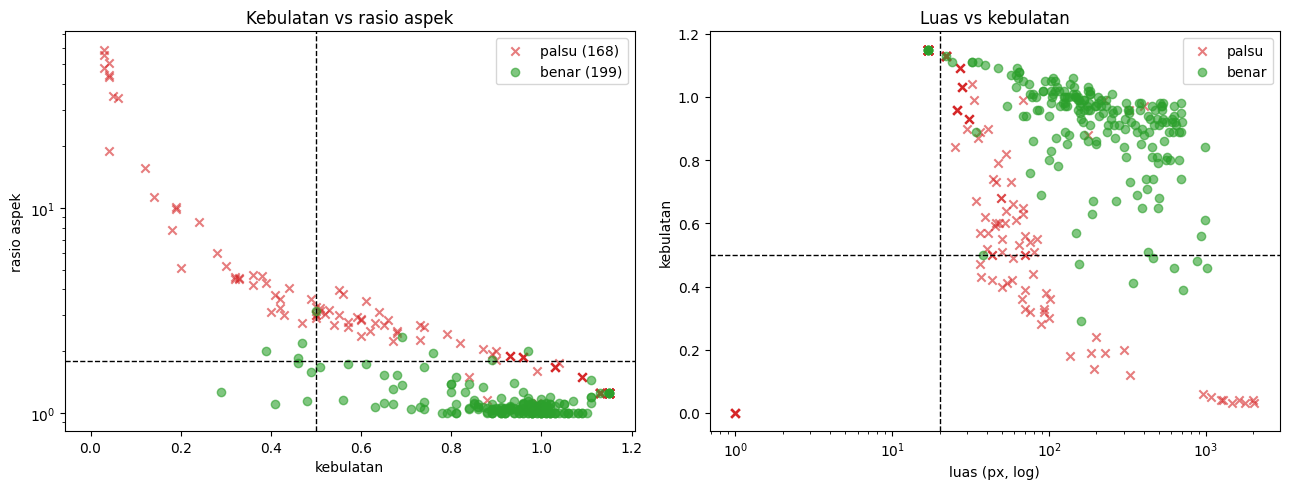

In [36]:
kom = []
for _, d in label.iterrows():
    _, md, mb = muat(d.nama_file)
    tk, lbl = ukur_komponen(BERSIH[d.nama_file])
    for _, r in tk.iterrows():
        di_acuan = (mb[lbl == r.label] > 0).mean()
        kom.append({**r.to_dict(), "nama": d.nama_file, "kelas": d.kelas, "porsi_di_acuan": di_acuan,
                    "status": "benar" if di_acuan > 0.5 else "palsu"})
kom = pd.DataFrame(kom)
kom.to_csv("../hasil/p6_komponen_benar_palsu.csv", index=False)
print(kom.status.value_counts().to_dict())
print(kom.groupby("status")[["luas_px", "kebulatan", "rasio_aspek"]].describe(percentiles=[.05, .5, .95]).T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for st, wr, mk in [("palsu", "tab:red", "x"), ("benar", "tab:green", "o")]:
    t = kom[kom.status == st]
    ax[0].scatter(t.kebulatan, t.rasio_aspek, c=wr, marker=mk, alpha=0.6, label=f"{st} ({len(t)})")
    ax[1].scatter(t.luas_px, t.kebulatan, c=wr, marker=mk, alpha=0.6, label=st)
ax[0].axvline(0.5, ls="--", c="k", lw=1); ax[0].axhline(1.8, ls="--", c="k", lw=1)
ax[0].set_xlabel("kebulatan"); ax[0].set_ylabel("rasio aspek"); ax[0].set_title("Kebulatan vs rasio aspek")
ax[0].legend(); ax[0].set_yscale("log")
ax[1].axvline(20, ls="--", c="k", lw=1); ax[1].axhline(0.5, ls="--", c="k", lw=1)
ax[1].set_xscale("log"); ax[1].set_xlabel("luas (px, log)"); ax[1].set_ylabel("kebulatan")
ax[1].set_title("Luas vs kebulatan"); ax[1].legend()
plt.tight_layout(); plt.savefig("../hasil/p6_sebar_benar_palsu.png", dpi=150); plt.show()

## Bagian 5. Integrasi: Modul `bercak.py`
### Pemilihan parameter `PB` (grid kecil)
Kombinasi k, SE, luas_min, dan batas_berat diuji lewat `bercak.analisis_daun` pada 60 citra. Grid ini memakai seluruh data berlabel, jadi akurasinya terlalu optimistis (lihat P5.2).

In [37]:
import importlib, itertools, bercak
importlib.reload(bercak)
KELAS_ACUAN = label.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"}).values
N_ACUAN = np.array([jumlah_komponen(muat(n)[2]) for n in label.nama_file])
baris = []
for k, bt, so, sc, lm in itertools.product([3, 4, 6], ["elips", "persegi"], [5, 7], [0, 5], [20, 40]):
    pb = dict(k=k, se_bentuk=bt, se_open=so, se_close=sc, luas_min=lm)
    hs = [bercak.analisis_daun(PRA[n], pb) for n in label.nama_file]
    per = np.array([h["persen_bercak"] for h in hs]); jum = np.array([h["jumlah_bercak"] for h in hs])
    for bb in [1.2, 2.0]:
        kel = np.where(per < 0.1, "Sehat", np.where(per < bb, "Bercak Ringan", "Bercak Berat"))
        baris.append({**pb, "batas_berat": bb, "galat_persen": np.abs(per - label.persen_bercak).mean(),
                      "galat_jumlah": np.abs(jum - N_ACUAN).mean(), "akurasi": (kel == KELAS_ACUAN).mean(),
                      "sehat_jadi_bercak": int(((KELAS_ACUAN == "Sehat") & (kel != "Sehat")).sum()),
                      "bercak_jadi_sehat": int(((KELAS_ACUAN != "Sehat") & (kel == "Sehat")).sum())})
grid = pd.DataFrame(baris).round(3)
grid.to_csv("../hasil/p6_grid_param_bercak.csv", index=False)
print(label.groupby("kelas").persen_bercak.agg(["min", "max"]))
grid.sort_values(["akurasi", "galat_jumlah", "galat_persen"], ascending=[False, True, True]).head(10)

         min   max
kelas             
berat   1.39  7.76
ringan  0.10  0.97
sehat   0.00  0.00


,k,se_bentuk,se_open,se_close,luas_min,batas_berat,galat_persen,galat_jumlah,akurasi,sehat_jadi_bercak,bercak_jadi_sehat
38,4,elips,5,5,40,1.2,0.689,0.483,0.950,0,3
2,3,elips,5,0,40,1.2,0.598,0.450,0.933,1,3
24,3,persegi,7,0,20,1.2,0.668,0.450,0.933,0,4
26,3,persegi,7,0,40,1.2,0.668,0.450,0.933,0,4
34,4,elips,5,0,40,1.2,0.668,0.483,0.933,0,4
6,3,elips,5,5,40,1.2,0.642,0.517,0.933,0,4
54,4,persegi,5,5,40,1.2,0.684,0.533,0.933,0,4
36,4,elips,5,5,20,1.2,0.681,0.700,0.933,2,2
28,3,persegi,7,5,20,1.2,0.696,0.550,0.917,0,4
30,3,persegi,7,5,40,1.2,0.696,0.550,0.917,0,4


### Kode 5.2 Evaluasi modul `bercak.py` (60 citra)

Galat absolut rerata persen bercak: 0.689
Korelasi persen prediksi vs acuan : 0.925
Akurasi kelas                     : 0.95
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             20              0      0
Bercak Ringan             0             17      3
Sehat                     0              0     20
kondisi
bayangan          0.83
gelap             1.00
kontras_rendah    0.92
normal            1.00
terang            1.00
Name: benar, dtype: float64


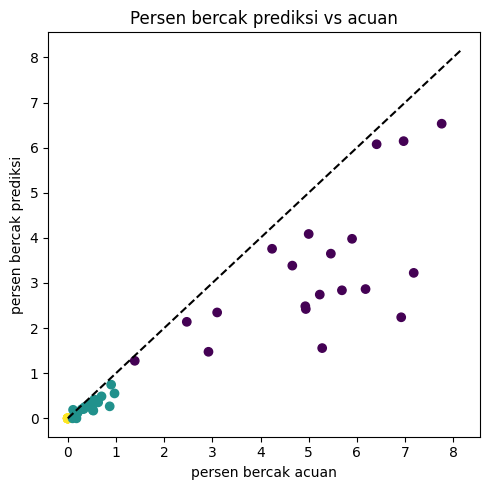

In [38]:
PB = {"luas_min": 40,       # Langkah 4.4: median luas komponen palsu 28 px, 95% komponen benar >= 35 px
      "batas_berat": 1.2}    # label.csv: ringan maks 0,97%, berat min 1,39% (lihat P5.2: terlalu optimistis)
bercak.simpan_param(PB)

baris, HASIL = [], {}
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(PRA[d.nama_file], PB)
    HASIL[d.nama_file] = h
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                     :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
batas = max(8, ev[["persen_acuan", "persen_prediksi"]].max().max() * 1.05)
plt.plot([0, batas], [0, batas], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.title("Persen bercak prediksi vs acuan"); plt.tight_layout()
plt.savefig("../hasil/p6_sebar_persen.png", dpi=150); plt.show()

#### Tabel 12. Ringkasan evaluasi modul `bercak.py`

In [39]:
akurasi_kondisi = ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean()
tabel12 = pd.DataFrame({"Nilai": [
    round((ev.persen_prediksi - ev.persen_acuan).abs().mean(), 3),
    round(ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1], 3),
    round((ev.kelas_prediksi == ev.kelas_acuan).mean(), 3),
    int(((ev.kelas_acuan == "Sehat") & (ev.kelas_prediksi != "Sehat")).sum()),
    int(((ev.kelas_acuan != "Sehat") & (ev.kelas_prediksi == "Sehat")).sum()),
    f"{akurasi_kondisi.idxmin()} ({akurasi_kondisi.min():.2f})"]},
    index=["Galat absolut rerata persen bercak", "Korelasi persen prediksi dan acuan", "Akurasi kelas",
           "Jumlah daun sehat yang dinilai berbercak", "Jumlah daun berbercak yang dinilai sehat",
           "Kondisi cahaya dengan akurasi terendah"])
tabel12.to_csv("../hasil/p6_tabel12_evaluasi.csv")
print("galat persen per kelas:"); print(ev.assign(g=(ev.persen_prediksi - ev.persen_acuan).abs()).groupby("kelas").g.mean().round(3))
tabel12

galat persen per kelas:
kelas
berat     1.871
ringan    0.197
sehat     0.000
Name: g, dtype: float64


,Nilai
Galat absolut rerata persen bercak,0.689
Korelasi persen prediksi dan acuan,0.925
Akurasi kelas,0.95
Jumlah daun sehat yang dinilai berbercak,0
Jumlah daun berbercak yang dinilai sehat,3
Kondisi cahaya dengan akurasi terendah,bayangan (0.83)


### Langkah 5.3 (Kerjakan sendiri) Analisis kesalahan: setiap citra yang salah kelas

3 citra salah kelas
       nama        kondisi   kelas_acuan kelas_prediksi  persen_acuan  persen_prediksi  jumlah_acuan  jumlah_prediksi
teh_034.png kontras_rendah Bercak Ringan          Sehat          0.18             0.00             1                0
teh_035.png       bayangan Bercak Ringan          Sehat          0.15             0.08             1                1
teh_040.png       bayangan Bercak Ringan          Sehat          0.10             0.00             1                0


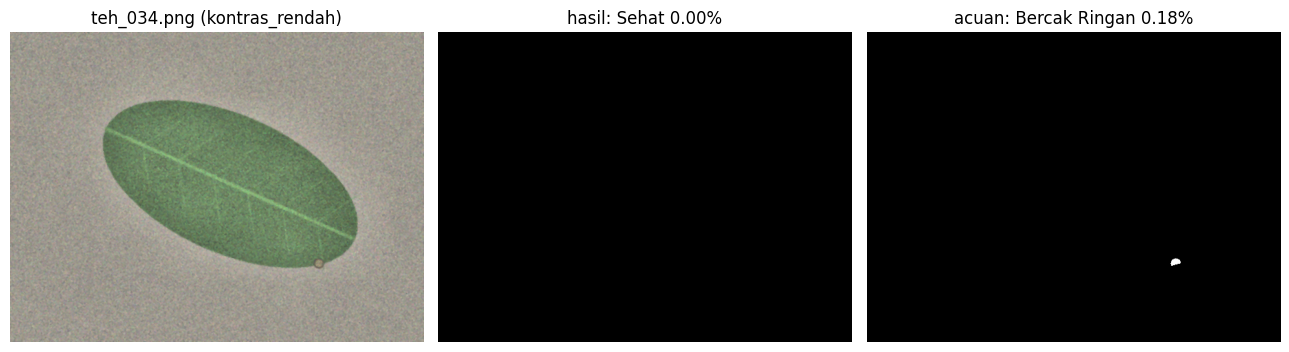

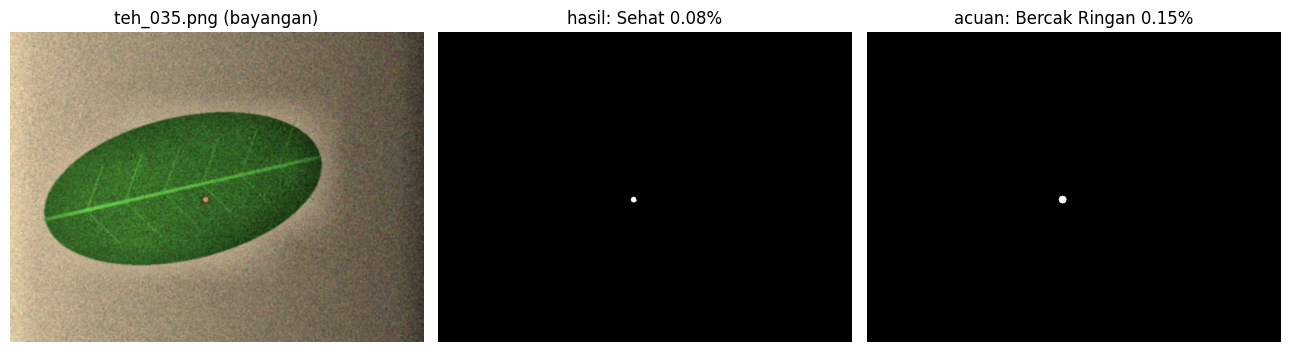

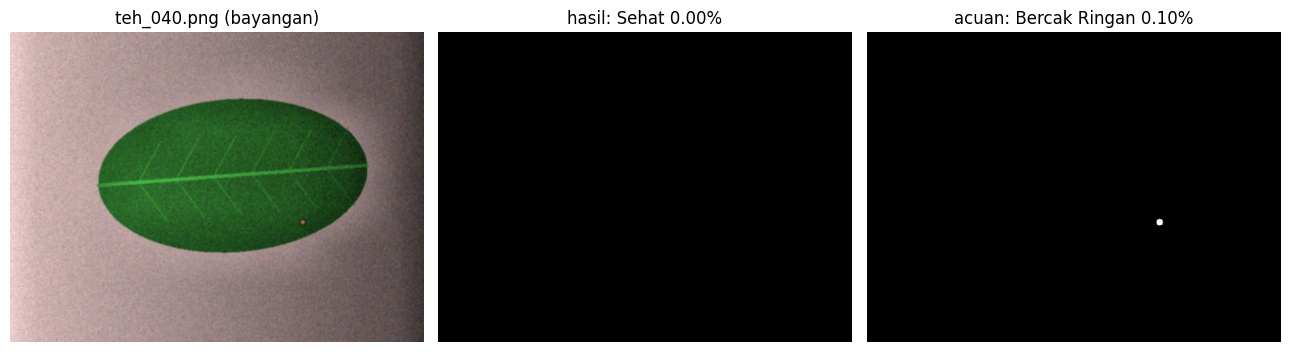

In [40]:
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print(f"{len(salah)} citra salah kelas")
print(salah[["nama", "kondisi", "kelas_acuan", "kelas_prediksi", "persen_acuan", "persen_prediksi",
             "jumlah_acuan", "jumlah_prediksi"]].to_string(index=False))
salah.to_csv("../hasil/p6_salah_kelas.csv", index=False)
for _, r in salah.iterrows():
    _, md, mb = muat(r.nama)
    h = HASIL[r.nama]
    tampil([PRA[r.nama], h["mask_bercak"], mb],
           [f"{r.nama} ({r.kondisi})", f"hasil: {r.kelas_prediksi} {r.persen_prediksi:.2f}%",
            f"acuan: {r.kelas_acuan} {r.persen_acuan:.2f}%"], ukuran=(13, 3.6))
    plt.savefig(f"../hasil/p6_salah_{r.nama[:7]}.png", dpi=110, bbox_inches="tight"); plt.show()